# 7 · Background experiments

The three experiments of the original programme (A: rank cost, B: drift sensor, C: value geometry), plus the
scaling run that produced the first log-linear decay result. See `docs/design/SPEC.md` for their gated design.

## A · Rank cost: how many directions carry refusal?

In [1]:
import sys, os; sys.path.insert(0, ".")
import numpy as np, pandas as pd
from kwm import *
setup(); pd.set_option("display.max_columns", 30); pd.set_option("display.width", 200)
rows = []
for m, s in (("Qwen3.5-2B", 0), ("Qwen3.5-2B", 1), ("Qwen3-1.7B", 0), ("Qwen3-1.7B", 1)):
    R = load(f"background/A_rank-cost_refusal-directions_{m}_seed{s}.json"); base = R["cells"][0]["refusal_margin"]["mean"]; spec = R["cells"][2]["spectrum"]
    row = {"model · seed": f"{m} · seed{s}", "stable rank": round(spec["stable_rank"], 2), "top-1 energy": round(spec["top1_frac"], 2)}
    for c in R["cells"][3:]:
        if c["mode"] == "standard" and c["k"] in (1, 2, 4, 12):
            m = c["margin"]["mean"] if isinstance(c["margin"], dict) else c["margin"]
            row[f"refusal removed, k={c['k']}"] = f"{100 * (base - m) / base:.0f}%"
    row["gates"] = ", ".join(f"{g['name']}={g['status']}" for g in R["gates"])
    rows.append(row)
pd.DataFrame(rows).set_index("model · seed")

,stable rank,top-1 energy,"refusal removed, k=1","refusal removed, k=2","refusal removed, k=4","refusal removed, k=12",gates
model · seed,,,,,,,
Qwen3.5-2B · seed0,8.37,0.12,68%,69%,70%,65%,"direction_reproducible=PASS, separability=PASS..."
Qwen3.5-2B · seed1,8.52,0.12,69%,70%,69%,65%,"direction_reproducible=PASS, separability=PASS..."
Qwen3-1.7B · seed0,1.31,0.76,71%,113%,50%,41%,"direction_reproducible=PASS, separability=PASS..."
Qwen3-1.7B · seed1,1.20,0.83,104%,101%,81%,83%,"direction_reproducible=PASS, separability=PASS..."


**Spectral rank does not predict vulnerability:** the 2B refusal subspace has stable rank ~8.4 (energy spread over many directions), yet one direction removes about two thirds of refusal and adding up to 12 directions adds nothing. Qwen3-1.7B (text-only, for comparison) is the opposite: rank ~1.3, and one or two directions remove essentially all refusal, but its larger-k cells are erratic. Its `ruler_headroom` gate is ABORT (the KL ruler could not resolve damage there), so its capability cost should not be read from KL.

## B · Drift sensor: a negative result with a diagnosis

In [2]:
for s in (0, 1):
    R = load(f"background/B_raw-refusal-alarm_Qwen3.5-0.8B_seed{s}.json")
    print(f"seed{s}: " + " | ".join(f"{g['name']}={g['status']} (value {g.get('value', float('nan')):.2f}, threshold {g.get('threshold')})" for g in R["gates"]) + f" | {R.get('note', '')}")

seed0: baseline_stationary=ADAPT (value 4.05, threshold 1.0) | baseline_reads=PASS (value 84.00, threshold 24.0) | degradation_present=PASS (value 53.33, threshold 10.0) | raw: 0 clean threshold(s); detrended: 0
seed1: baseline_stationary=ADAPT (value 4.05, threshold 1.0) | baseline_reads=PASS (value 84.00, threshold 24.0) | degradation_present=PASS (value 44.72, threshold 10.0) | raw: 0 clean threshold(s); detrended: 0


A threshold alarm on the raw refusal level cannot be calibrated: the baseline drifts by ~4 SD even over 84 reads, and no threshold both catches damage and stays quiet on the control. The decay turned out to be regular enough to **forecast** instead — the basis of replay on demand.

## C · Value geometry: are the directions real?

In [3]:
rows = []
for m, s in [(m, s) for m in ("Qwen3-1.7B", "Qwen3.5-0.8B", "Qwen3.5-2B") for s in (0, 1)]:
    R = load(f"background/C_refusal-vs-value-directions_{m}_seed{s}.json"); g = R["gates"]
    rows.append({"model · seed": f"{m} · seed{s}",
                 "refusal split-half °": g[0].get("value"), "refusal separability d": g[1].get("value"),
                 "values split-half °": g[2].get("value"), "values separability d": g[3].get("value"),
                 "all gates": all(x["status"] == "PASS" for x in g)})
pd.DataFrame(rows).set_index("model · seed").round(2)

,refusal split-half °,refusal separability d,values split-half °,values separability d,all gates
model · seed,,,,,
Qwen3-1.7B · seed0,7.17,4.29,26.78,3.88,True
Qwen3-1.7B · seed1,5.11,3.61,26.40,3.15,True
Qwen3.5-0.8B · seed0,12.26,3.90,24.78,3.20,True
Qwen3.5-0.8B · seed1,12.56,3.43,19.86,3.08,True
Qwen3.5-2B · seed0,8.24,6.40,15.92,4.61,True
Qwen3.5-2B · seed1,8.34,6.12,13.55,4.50,True


All three models give reproducible, separable refusal and value directions (split-half angles far below the 90° of unrelated directions). Value directions are consistently noisier than refusal ones (14–27° vs 5–13°), matching the need for more items in notebook 2.

## The first scaling run (0.8B, code, Colab) — now with its 2M-token checkpoint
This run measured refusal on harmful requests only (a mean margin rather than the later harmful−harmless gap), so its numbers are not directly comparable with notebook 1.

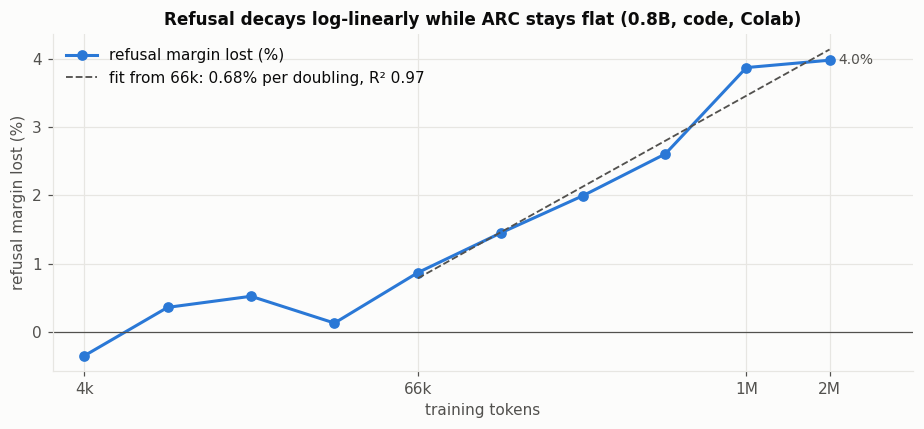

ARC accuracy at each checkpoint: 0.832 0.842 0.842 0.848 0.844 0.840 0.838 0.840 0.834 0.840
fit 66k-1M (THESIS_LOG entry 1): 0.728% per doubling, R² 0.96 | with the 2M point: 0.680, R² 0.97
1M -> 2M added 0.11 points; the 66k-1M law predicted 0.73


In [4]:
S = load("erosion/D1_decay-law_Qwen3.5-0.8B_code_gentle_2M-tokens.json")
t, y, acc = [r["tokens"] for r in S], [r["refusal_drop_pct"] for r in S], [r["acc"] for r in S]
k = [i for i, x in enumerate(t) if x >= 65536]                      # after the initial flat phase, as in THESIS_LOG entry 1
a, b, r2 = decay_fit([t[i] for i in k], [y[i] for i in k])
a1, b1, r21 = decay_fit([t[i] for i in k[:-1]], [y[i] for i in k[:-1]])
fig, ax = plt.subplots(figsize=(8.5, 4))
ax.plot(t, y, marker="o", color=BLUE, label="refusal margin lost (%)")
xs = np.array([t[k[0]], t[-1]]); ax.plot(xs, a * np.log2(xs) + b, color=INK2, ls="--", lw=1.2, label=f"fit from 66k: {a:.2f}% per doubling, R² {r2:.2f}")
end_label(ax, t[-1], y[-1], f"{y[-1]:.1f}%"); ax.axhline(0, color=INK2, lw=0.8)
tok_axis(ax, [t[0], t[4], t[-2], t[-1]]); ax.set_xlim(t[0] / 1.3, t[-1] * 2)
ax.set_xlabel("training tokens"); ax.set_ylabel("refusal margin lost (%)"); ax.legend(loc="upper left")
ax.set_title("Refusal decays log-linearly while ARC stays flat (0.8B, code, Colab)"); fig.tight_layout(); plt.show()
print("ARC accuracy at each checkpoint:", " ".join(f"{x:.3f}" for x in acc))
print(f"fit 66k-1M (THESIS_LOG entry 1): {a1:.3f}% per doubling, R² {r21:.2f} | with the 2M point: {a:.3f}, R² {r2:.2f}")
print(f"1M -> 2M added {y[-1] - y[-2]:.2f} points; the 66k-1M law predicted {a1:.2f}")

Refusal barely moves for the first ~32k tokens, then decays log-linearly. The 2M checkpoint added only 0.1 point where the law predicted ~0.7: one point, so possibly noise, possibly the start of flattening. Forecasting for replay on demand must be tested over longer runs before it is trusted (notebook 5 goes to 8M tokens).

In [5]:
W = load("erosion/D1_regime-sweep_lr-x-steps_Qwen3.5-0.8B_code-vs-chat.json")
pd.DataFrame([{"LR": w["lr"], "steps": w["steps"], "code: ARC drop pp": round(w["ood"]["acc_drop_pp"], 1), "chat: ARC drop pp": round(w["benign"]["acc_drop_pp"], 1),
               "code: refusal drop %": round(w["ood"]["refusal_drop_pct"], 2), "verdict": w["why"]} for w in W])

,LR,steps,code: ARC drop pp,chat: ARC drop pp,code: refusal drop %,verdict
0,0.00003,8,0.5,2.5,-0.14,no damage
1,0.00003,16,2.0,1.0,-0.17,no damage
2,0.00003,32,1.5,1.0,0.06,no damage
3,0.00003,64,0.5,1.0,0.98,no damage
4,0.00010,8,1.5,0.0,0.36,no damage
5,0.00010,16,0.0,0.0,0.41,no damage


The window sweep brackets the regime from below: at these learning rates and step counts nothing measurable happens, which is why later runs moved to longer and stronger training.